# Catalysis case study: small data, huge feature space

This is the problem iBART was designed for. We have the binding energies of 91
single metal atoms on oxide supports, and 59 primary features describing the
metal and the oxide (formation enthalpies, vacancy energies, electronegativities,
ionization energies, ...). The goal is a **compact, physically interpretable
formula** for the binding energy, not a black box.

That is hard for two reasons:

- the descriptor space is enormous: one round of binary operators on 59 features
  gives thousands of candidates, and a second round gives millions;
- there are only 91 data points, so most of those candidates will fit the noise.

iBART handles this by never building the full space: it screens after every
round, so each round of operators only acts on descriptors that survived.

The published result (Liu et al. 2022; Ye et al. 2024) is that the single best
descriptor is `|Hfo/Oxv|`, the ratio of the oxide formation enthalpy to the
oxygen vacancy energy.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from jax_ibart import IBart, sparsify
from jax_ibart.datasets import load_metal_support

X, y, names, units = load_metal_support()
print("X:", X.shape, " y:", y.shape)
print("first features:", names[:8], "...")
print("units matrix:", units.shape, "(one row of unit exponents per feature)")

X: (91, 59)  y: (91,)
first features: ['Hfo', 'm_Z', 's_Z', 'o_Z', 'm_Chi_P', 's_Chi_P', 'o_Chi_P', 'm_Chi_MB'] ...
units matrix: (59, 12) (one row of unit exponents per feature)


## No single primary feature is enough

The best single primary feature has |r| of about 0.74 with the binding energy.
The answer has to be a combination.

top primaries by |r|: [('s_ion_4', np.float64(0.742)), ('Oxv', np.float64(0.734)), ('s_ion_3', np.float64(0.7)), ('s_EA', np.float64(0.65)), ('s_Z', np.float64(0.648))]


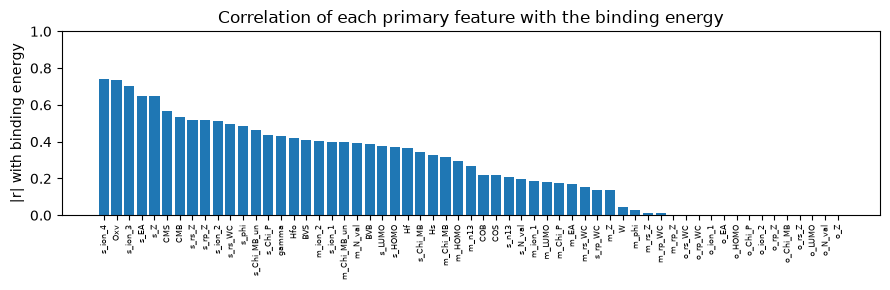

In [2]:
with np.errstate(invalid="ignore"):  # a few primaries are constant -> r undefined
    r = np.array([np.corrcoef(X[:, j], y)[0, 1] for j in range(X.shape[1])])
r = np.nan_to_num(r)
order = np.argsort(-np.abs(r))
print("top primaries by |r|:", [(names[j], round(abs(r[j]), 3)) for j in order[:5]])

fig, ax = plt.subplots(figsize=(9, 3))
ax.bar(range(len(r)), np.abs(r[order]), color="C0")
ax.set_xticks(range(len(r)), [names[j] for j in order], rotation=90, fontsize=6)
ax.set_ylabel("|r| with binding energy")
ax.set_ylim(0, 1)
ax.set_title("Correlation of each primary feature with the binding energy")
fig.tight_layout()
plt.show()

## Fit with the faithful BART backend

We use the `bart` backend (the BART-G.SE permutation screen of Bleich et al.
2014, run with [`bartz`](https://github.com/Gattocrucco/bartz)) with the default
schedule `("b", "u", "b")`: binary, then unary, then binary operators, with a
screen after each.

Two settings matter:

- `units=units` turns on the dimensional-analysis filter, so physically
  meaningless descriptors (adding an energy to a length) are never built.
- `alpha=0.25` makes the screen permissive. A screen in iBART must above all
  avoid **false negatives**: a descriptor dropped in round 1 can never be
  combined in round 2. Keeping a few extra descriptors is cheap; losing a true one
  is not.

This takes about half a minute on a laptop CPU.

In [3]:
import time

t0 = time.perf_counter()
model = IBart(backend="bart", alpha=0.25, n_perm=25, n_tree=40, n_draw=400,
              n_burn=400, n_keep=15, max_dim=3, seed=0)
model.fit(X, y, names, units=units)
print(f"fit time: {time.perf_counter() - t0:.0f} s")

fit time: 17 s


## Grow, prune, grow, prune

The history shows why this is tractable. The first binary round builds a few
thousand candidates (the unit filter has already removed most of the
dimensionally inconsistent ones), and the screen keeps under a hundred. Each
later round starts from that small pool instead of the full space.

In [4]:
def plot_history(history, ax=None, title="Descriptor pool at each stage"):
    """Bar chart of pool size generated vs kept at each pipeline stage."""
    import matplotlib.pyplot as plt
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 3.2))
    labels = {"primary": "primary\nfeatures", "u": "unary\nops", "b": "binary\nops",
              "l0": "LASSO + l0"}
    xs = np.arange(len(history))
    gen = [h["generated"] for h in history]
    kept = [h["kept"] for h in history]
    ax.bar(xs - 0.2, gen, 0.4, label="generated", color="C0")
    ax.bar(xs + 0.2, kept, 0.4, label="kept after screening", color="C1")
    for x, g, k in zip(xs, gen, kept):
        ax.text(x - 0.2, g, f"{g:,}", ha="center", va="bottom", fontsize=8)
        ax.text(x + 0.2, k, f"{k:,}", ha="center", va="bottom", fontsize=8)
    ax.set_yscale("log")
    ax.set_xticks(xs, [labels.get(h["stage"], h["stage"]) for h in history])
    ax.set_ylabel("number of descriptors")
    ax.set_title(title)
    ax.legend(loc="upper right", fontsize=8)
    return ax

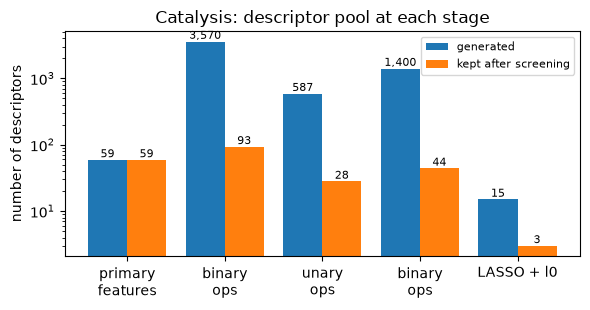

In [5]:
plot_history(model.history_, title="Catalysis: descriptor pool at each stage")
plt.tight_layout()
plt.show()

## The discovered model

BIC chose three descriptors. Two of them are built on `|Hfo/Oxv|`, the published
canonical descriptor.

In [6]:
pred = model.predict(X)
rmse = np.sqrt(((y - pred) ** 2).mean())
r2 = 1 - ((y - pred) ** 2).sum() / ((y - y.mean()) ** 2).sum()
print(f"in-sample RMSE = {rmse:.3f} eV,  R^2 = {r2:.3f}\n")
print(f"  {model.coef_[0]:+.4g}")
for desc, coef in zip(model.descriptors_, model.coef_[1:]):
    print(f"  {coef:+.4g} * {desc}")

in-sample RMSE = 0.822 eV,  R^2 = 0.919

  -0.3507
  -0.002754 * BVB**2*Hfo**2/log(Hs*m_Chi_MB)
  -0.4844 * exp(BVS/Hfo)*Abs(Hfo/Oxv)
  -0.3449 * sin(pi*Oxv*s_phi)*Abs(Hfo/Oxv)


## Comparison with the published result

`model.pool_` is the screened pool the final stage chose from. Re-running the l0
search on it with 1, 2 and 3 descriptors gives the accuracy-versus-complexity
trade-off, which we compare with the published l0 models.

In [7]:
import json

from jax_ibart.datasets import DATA_DIR

oracle = json.loads((DATA_DIR / "oracle_ibart.json").read_text())
published = oracle["lzero_in_sample_rmse"][:3]

P = np.asarray(model.pool_.X, dtype=np.float64)
cand = sparsify.lasso_screen(P, y, n_keep=15)
ours, best = [], {}
for k in (1, 2, 3):
    loc, coef = sparsify.l0_best_subset(P[:, cand], y, max_dim=k, score="bic")
    A = np.column_stack([np.ones(len(y))] + [P[:, cand[i]] for i in loc])
    ours.append(np.sqrt(((y - A @ coef) ** 2).mean()))
    best[k] = A[:, 1:]
    print(f"k={k}: RMSE {ours[-1]:.3f} (published {published[k-1]:.3f})  "
          f"{[str(model.pool_.exprs[cand[i]]) for i in loc]}")
print()
print("published k=1:", oracle["lzero_1"])
print("published k=3:", oracle["lzero_3"])

k=1: RMSE 1.012 (published 0.929)  ['exp(BVS/Hfo)*Abs(Hfo/Oxv)']
k=2: RMSE 0.930 (published 0.664)  ['exp(BVS/Hfo)*Abs(Hfo/Oxv)', 'exp(s_HOMO*s_phi)*sin(pi*s_ion_3/m_LUMO)']
k=3: RMSE 0.822 (published 0.624)  ['BVB**2*Hfo**2/log(Hs*m_Chi_MB)', 'exp(BVS/Hfo)*Abs(Hfo/Oxv)', 'sin(pi*Oxv*s_phi)*Abs(Hfo/Oxv)']

published k=1: ['abs((Hfo/Oxv))']
published k=3: ['(s_EA*Hf)', 'abs((Hfo/Oxv))', 'abs(((m_n13/m_N_val)/Oxv))']


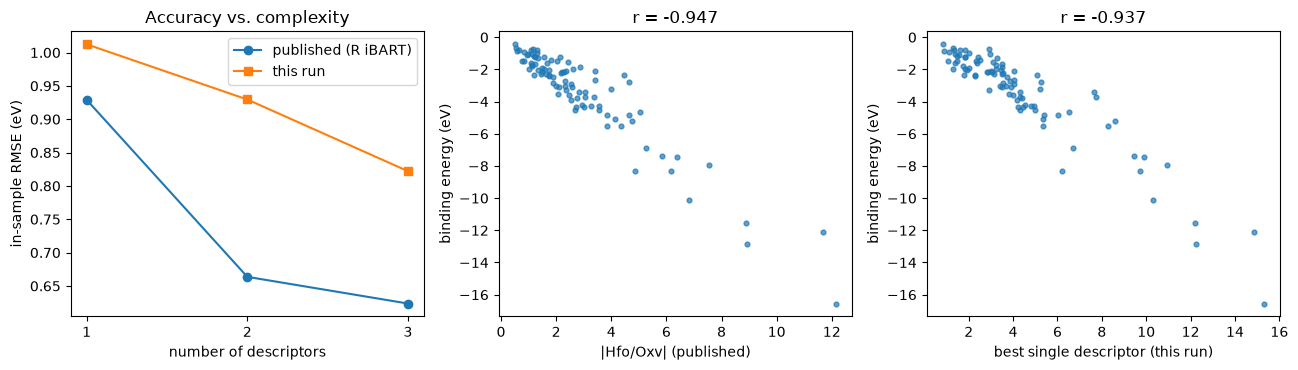

In [8]:
H, O = X[:, names.index("Hfo")], X[:, names.index("Oxv")]
ratio = np.abs(H / O)
best1 = best[1][:, 0]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
ks = [1, 2, 3]
axes[0].plot(ks, published, "o-", label="published (R iBART)")
axes[0].plot(ks, ours, "s-", label="this run")
axes[0].set_xticks(ks)
axes[0].set_xlabel("number of descriptors")
axes[0].set_ylabel("in-sample RMSE (eV)")
axes[0].set_title("Accuracy vs. complexity")
axes[0].legend()

for ax, v, lab in [(axes[1], ratio, "|Hfo/Oxv| (published)"),
                   (axes[2], best1, "best single descriptor (this run)")]:
    rr = np.corrcoef(v, y)[0, 1]
    ax.scatter(v, y, s=12, alpha=0.7)
    ax.set_xlabel(lab)
    ax.set_ylabel("binding energy (eV)")
    ax.set_title(f"r = {rr:+.3f}")
fig.tight_layout()
plt.show()

Compare the middle panel with the bar chart above: no primary feature had |r|
above 0.75, and this one ratio of two of them has |r| of about 0.95. That
collapse is what iBART is for.

Every model this run finds is built on the same `Hfo`/`Oxv` coupling as the
published one, but the published models are more accurate at each size: our
three-descriptor model sits between the published one- and two-descriptor
models. Even our best *single* descriptor (`exp(BVS/Hfo)*|Hfo/Oxv|`) is a little
worse than the published `|Hfo/Oxv|`. The main reason: `|Hfo/Oxv|` survives the first
screen, but the last binary round replaces the pool with products of its
members, so the bare ratio is not in the final pool. The R package keeps a
running union of everything every screen has selected. `IBart(...,
carry_selected=True)` does the same; it keeps `|Hfo/Oxv|` in the pool and
changes the final descriptors. The default stays off because the validated
results in [the oracle cross-check](../oracle-crosscheck.md) were made without it.

All RMSEs here are in-sample. With 91 points and thousands of candidates,
check models out of sample before trusting the third descriptor (see the
[uncertainty notebook](08_uncertainty.ipynb)).

## The fast differentiable backend

The `diff` backend replaces each BART screen with a gated neural network trained
by gradient descent. It is useful for exploring quickly, but on this
small, high-dimensional problem it finds a less accurate model than `bart`.

In [9]:
t0 = time.perf_counter()
fast = IBart(backend="diff", max_dim=3, n_keep=10, seed=0, steps=1000,
             l0=0.03).fit(X, y, names, units=units)
fp = fast.predict(X)
print(f"diff: {time.perf_counter() - t0:.0f} s, "
      f"RMSE {np.sqrt(((y - fp) ** 2).mean()):.3f} eV  (bart above: {rmse:.3f})")
for d_ in fast.descriptors_:
    print("  ", d_)

diff: 4 s, RMSE 1.090 eV  (bart above: 0.822)
   Hf**2/Oxv**2 + Abs(Hf/Oxv)
   m_Chi_MB**2/(Oxv**2*Abs(m_Chi_MB/Oxv))


## References and data provenance

- **Dataset** (`load_metal_support`): the single-atom catalysis data (91
  metal/oxide binding energies, 59 features) shipped with the R `iBART`
  package; the underlying DFT data are from the Senftle group's MIT-licensed
  [`Metal-Oxide-LASSO-lo`](https://github.com/tsenftle/Metal-Oxide-LASSO-lo)
  repository. See [`data/README.md`](https://github.com/jkitchin/jax-ibart/blob/main/src/jax_ibart/data/README.md).
- **Reference result** (`oracle_ibart.json`): the published iBART l0 descriptors
  and RMSEs, from the papers below.
- **Method**: C.-Y. Liu, S. Ye, M. Li, T. P. Senftle, *J. Chem. Phys.* **156**,
  164105 (2022); S. Ye, T. P. Senftle, M. Li, *JASA* **119**:81-94 (2024),
  arXiv:2110.10195.
- Full bibliography: [docs/references.md](../references.md). Detailed comparison
  with the reference implementation: [docs/oracle-crosscheck.md](../oracle-crosscheck.md).